<a href="https://colab.research.google.com/github/kky-zs/100-days-ml/blob/main/notebooks/phase-1-ml-core/day-001-training-framework.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kky-zs/100-days-ml/blob/main/notebooks/phase-1-ml-core/day-001-training-framework.ipynb)

# A reusable PyTorch Trainer

**Goal**: build a Trainer class that handles the train/validation loop, metrics history, checkpoints, resuming, seeding, device handling, early stopping and an LR scheduler. Test it on Fashion-MNIST with a small MLP.

## Part 1: Setup and imports

In [1]:
import random
import time
from dataclasses import dataclass, asdict # gives a clean config object
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

print("torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

torch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


---

## Part 2: Reproducibility (seeding)

NN training uses randomness in weight initialization, data shuffling, dropout and the train/val split.

In [2]:
def seed_everything(seed: int = 42, deterministic: bool = False) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything(42)

---

## Part 3: Data

**Fashion-MNIST**: 60,000 training and 10,000 test grayscale images (28×28), 10 clothing classes.

ToTensor() converts images to float tensors in [0, 1].

Normalize(mean, std) standardizes them (0.2860 and 0.3530 are the dataset’s pixel mean and std).

We split the training set into 55,000 train / 5,000 validation. The Generator makes the split and the shuffling reproducible.

DataLoader batches the data. num_workers loads batches in parallel, and pin_memory=True speeds up CPU-to-GPU transfers.

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,)),
])

full_train = datasets.FashionMNIST(root="data", train=True, download=True, transform=transform)
test_set = datasets.FashionMNIST(root="data", train=False, download=True, transform=transform)

g = torch.Generator().manual_seed(42)
train_set, val_set = random_split(full_train, [55_000, 5_000], generator=g)

BATCH_SIZE = 128
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=True, generator=g)
val_loader = DataLoader(val_set, batch_size=256, shuffle=False,
                        num_workers=2, pin_memory=True)
test_loader = DataLoader(test_set, batch_size=256, shuffle=False,
                         num_workers=2, pin_memory=True)

print(len(train_set), len(val_set), len(test_set))

55000 5000 10000


batch shape: torch.Size([128, 1, 28, 28]) | labels shape: torch.Size([128])


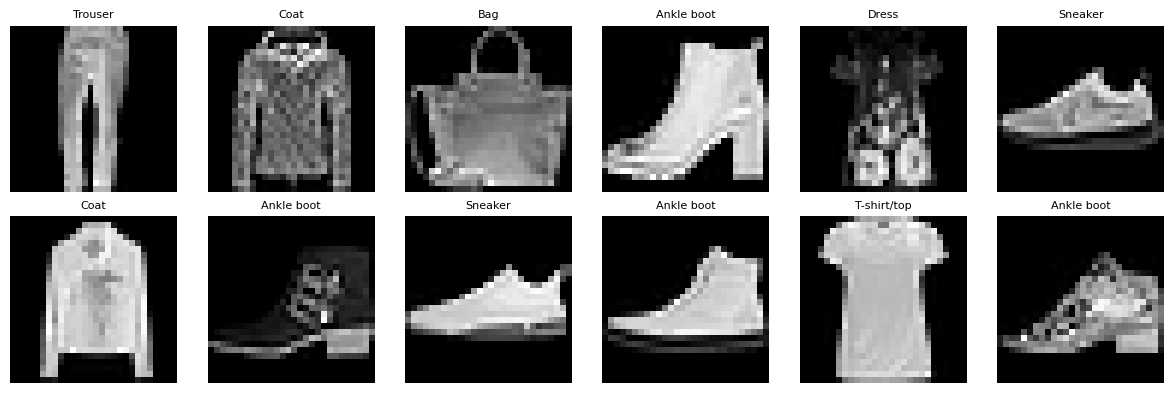

In [4]:
# look at the data
class_names = full_train.classes
x_batch, y_batch = next(iter(train_loader))
print("batch shape:", x_batch.shape, "| labels shape:", y_batch.shape)

fig, axes = plt.subplots(2, 6, figsize=(12, 4))
for ax, img, label in zip(axes.ravel(), x_batch, y_batch):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(class_names[label], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

---

## Part 4: The model

A simple MLP: flatten the image, then Linear → ReLU → Dropout blocks, then a final Linear layer with 10 outputs.

The outputs are logits (raw scores). We do not apply softmax here, because nn.CrossEntropyLoss applies log-softmax internally and does it in a numerically stable way.

Dropout randomly zeroes activations during training to reduce overfitting. It is switched off in eval mode.

In [5]:
class MLP(nn.Module):
    def __init__(self, in_features=28 * 28, hidden=(256, 128), num_classes=10, dropout=0.2):
        super().__init__()
        layers = [nn.Flatten()]
        prev = in_features
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

model = MLP()
print(model)
print("parameters:", sum(p.numel() for p in model.parameters()))

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.2, inplace=False)
    (7): Linear(in_features=128, out_features=10, bias=True)
  )
)
parameters: 235146


---

## Part 5: The plain training loop

1. **optimizer.zero_grad()** clears old gradients (PyTorch accumulates them by default).
2. Forward pass: **logits = model(x)**.
3. Loss: **criterion(logits, y)**.
4. **loss.backward()** computes gradients.
5. **optimizer.step()** updates the weights.

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = MLP().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)

model.train()
running_loss, correct, total = 0.0, 0, 0
for x, y in train_loader:
    x, y = x.to(device), y.to(device)

    optimizer.zero_grad()
    logits = model(x)
    loss = criterion(logits, y)
    loss.backward()
    optimizer.step()

    running_loss += loss.item() * y.size(0)
    correct += (logits.argmax(dim=1) == y).sum().item()
    total += y.size(0)

print(f"train loss {running_loss / total:.4f} | train acc {correct / total:.4f}")

train loss 0.5353 | train acc 0.8065


---

## Part 6: The evaluation loop

**model.eval()** changes the behaviour of layers: dropout turns off and BatchNorm uses running statistics.

**torch.no_grad()** stops PyTorch from building the computation graph, which saves memory and time.

Forgetting model.eval() gives noisy, worse validation numbers. Forgetting no_grad() wastes memory.

In [7]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = criterion(logits, y)
        total_loss += loss.item() * y.size(0)
        correct += (logits.argmax(dim=1) == y).sum().item()
        n += y.size(0)
    return total_loss / n, correct / n

print(evaluate(model, val_loader, criterion, device))

(0.39752581315040586, 0.8598)


---

## Part 7: The config

All hyperparameters and settings live in one object, not scattered across cells. **Benefits**: you can log it, save it inside checkpoints, and change one thing between experiments without hunting through code. **dataclass** gives defaults, readable printing and **asdict()** for free.

In [8]:
@dataclass
class TrainConfig:
    epochs: int = 10
    lr: float = 1e-3
    weight_decay: float = 1e-2
    seed: int = 42
    device: str = "auto"           # "auto", "cpu" or "cuda"
    ckpt_dir: str = "checkpoints"
    patience: int = 3              # 0 disables early stopping
    use_scheduler: bool = True     # one-cycle lr schedule, helps convergence
    grad_clip: float | None = 1.0  # clips the grad norm, prevents exploding grad
    log_every: int = 1             # how often to print

---

## Part 8: The Trainer

In [9]:
class Trainer:
    def __init__(self, model, train_loader, val_loader, config: TrainConfig,
                 criterion=None, optimizer=None, scheduler=None):
        self.cfg = config
        self.device = self._resolve_device(config.device)
        self.model = model.to(self.device)
        self.train_loader = train_loader
        self.val_loader = val_loader
        self.criterion = criterion or nn.CrossEntropyLoss()
        self.optimizer = optimizer or torch.optim.AdamW(
            self.model.parameters(), lr=config.lr, weight_decay=config.weight_decay
        )
        if scheduler is None and config.use_scheduler:
            scheduler = torch.optim.lr_scheduler.OneCycleLR(
                self.optimizer, max_lr=config.lr,
                total_steps=config.epochs * len(train_loader),
            )
        self.scheduler = scheduler

        self.history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr": []}
        self.start_epoch = 0
        self.best_val_loss = float("inf")
        self.epochs_no_improve = 0
        Path(config.ckpt_dir).mkdir(parents=True, exist_ok=True)

    @staticmethod
    def _resolve_device(name: str) -> torch.device: # "auto" picks the GPU if available.
        if name == "auto":
            return torch.device("cuda" if torch.cuda.is_available() else "cpu")
        return torch.device(name)

    def _run_epoch(self, loader, train: bool):
        self.model.train(train)
        total_loss, correct, n = 0.0, 0, 0
        for x, y in loader:
            x = x.to(self.device, non_blocking=True)
            y = y.to(self.device, non_blocking=True)

            with torch.set_grad_enabled(train):
                logits = self.model(x)
                loss = self.criterion(logits, y)

            if train:
                self.optimizer.zero_grad(set_to_none=True)
                loss.backward()
                if self.cfg.grad_clip is not None:
                    nn.utils.clip_grad_norm_(self.model.parameters(), self.cfg.grad_clip)
                self.optimizer.step()
                if self.scheduler is not None:
                    self.scheduler.step() # steps once per batch

            bs = y.size(0)
            total_loss += loss.item() * bs
            correct += (logits.argmax(dim=1) == y).sum().item()
            n += bs
        return total_loss / n, correct / n

    def fit(self):
        for epoch in range(self.start_epoch, self.cfg.epochs):
            t0 = time.time()
            tr_loss, tr_acc = self._run_epoch(self.train_loader, train=True)
            va_loss, va_acc = self._run_epoch(self.val_loader, train=False)
            lr = self.optimizer.param_groups[0]["lr"]

            for key, val in zip(self.history, (tr_loss, tr_acc, va_loss, va_acc, lr)):
                self.history[key].append(val)

            improved = va_loss < self.best_val_loss
            if improved:
                self.best_val_loss = va_loss
                self.epochs_no_improve = 0
            else:
                self.epochs_no_improve += 1

            self.save_checkpoint("last.pt", epoch)
            if improved:
                self.save_checkpoint("best.pt", epoch)

            if (epoch + 1) % self.cfg.log_every == 0:
                print(f"epoch {epoch + 1:02d}/{self.cfg.epochs} | "
                      f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
                      f"val loss {va_loss:.4f} acc {va_acc:.4f} | "
                      f"lr {lr:.2e} | {time.time() - t0:.1f}s"
                      f"{' *' if improved else ''}")

            if self.cfg.patience and self.epochs_no_improve >= self.cfg.patience:
                print(f"Early stopping at epoch {epoch + 1}")
                break
        return self.history

    def evaluate(self, loader):
        return self._run_epoch(loader, train=False)

    @torch.no_grad()
    def predict(self, loader):
        self.model.eval()
        all_logits, all_labels = [], []
        for x, y in loader:
            all_logits.append(self.model(x.to(self.device)).cpu())
            all_labels.append(y)
        return torch.cat(all_logits), torch.cat(all_labels)

    def save_checkpoint(self, name: str, epoch: int):
        torch.save({
            "epoch": epoch,
            "model_state": self.model.state_dict(),
            "optimizer_state": self.optimizer.state_dict(), # Adam keeps moving averages
            "scheduler_state": self.scheduler.state_dict() if self.scheduler else None,
            "history": self.history,
            "best_val_loss": self.best_val_loss,
            "epochs_no_improve": self.epochs_no_improve,
            "config": asdict(self.cfg),
        }, Path(self.cfg.ckpt_dir) / name)

    def load_checkpoint(self, name: str):
        ckpt = torch.load(Path(self.cfg.ckpt_dir) / name, map_location=self.device)
        self.model.load_state_dict(ckpt["model_state"])
        self.optimizer.load_state_dict(ckpt["optimizer_state"])
        if self.scheduler is not None and ckpt["scheduler_state"] is not None:
            self.scheduler.load_state_dict(ckpt["scheduler_state"])
        self.history = ckpt["history"]
        self.best_val_loss = ckpt["best_val_loss"]
        self.epochs_no_improve = ckpt["epochs_no_improve"]
        self.start_epoch = ckpt["epoch"] + 1
        print(f"Loaded {name}: continuing from epoch {self.start_epoch + 1}")

---

# Part 9: Train

The * marks epochs where validation loss improved (and best.pt was saved).

In [10]:
seed_everything(42)
cfg = TrainConfig(epochs=10)
trainer = Trainer(MLP(), train_loader, val_loader, cfg)
history = trainer.fit()

epoch 01/10 | train loss 1.0881 acc 0.6639 | val loss 0.5433 acc 0.7988 | lr 2.80e-04 | 18.6s *
epoch 02/10 | train loss 0.4761 acc 0.8270 | val loss 0.4111 acc 0.8510 | lr 7.61e-04 | 12.8s *
epoch 03/10 | train loss 0.4068 acc 0.8507 | val loss 0.3757 acc 0.8620 | lr 1.00e-03 | 13.1s *
epoch 04/10 | train loss 0.3603 acc 0.8682 | val loss 0.3621 acc 0.8624 | lr 9.50e-04 | 12.7s *
epoch 05/10 | train loss 0.3294 acc 0.8792 | val loss 0.3507 acc 0.8720 | lr 8.11e-04 | 11.6s *
epoch 06/10 | train loss 0.3044 acc 0.8873 | val loss 0.3207 acc 0.8846 | lr 6.11e-04 | 11.7s *
epoch 07/10 | train loss 0.2784 acc 0.8969 | val loss 0.3145 acc 0.8844 | lr 3.88e-04 | 17.4s *
epoch 08/10 | train loss 0.2588 acc 0.9038 | val loss 0.3050 acc 0.8904 | lr 1.88e-04 | 12.2s *
epoch 09/10 | train loss 0.2397 acc 0.9116 | val loss 0.2967 acc 0.8902 | lr 4.93e-05 | 11.4s *
epoch 10/10 | train loss 0.2323 acc 0.9138 | val loss 0.2969 acc 0.8924 | lr 4.27e-09 | 11.9s


In [11]:
# Final test evaluation, using the best checkpoint.
# This is the only time we touch the test set.

trainer.load_checkpoint("best.pt")
test_loss, test_acc = trainer.evaluate(test_loader)
print(f"TEST loss {test_loss:.4f} | TEST acc {test_acc:.4f}")

Loaded best.pt: continuing from epoch 10
TEST loss 0.3103 | TEST acc 0.8884


---

## Part 10: Plot the curves

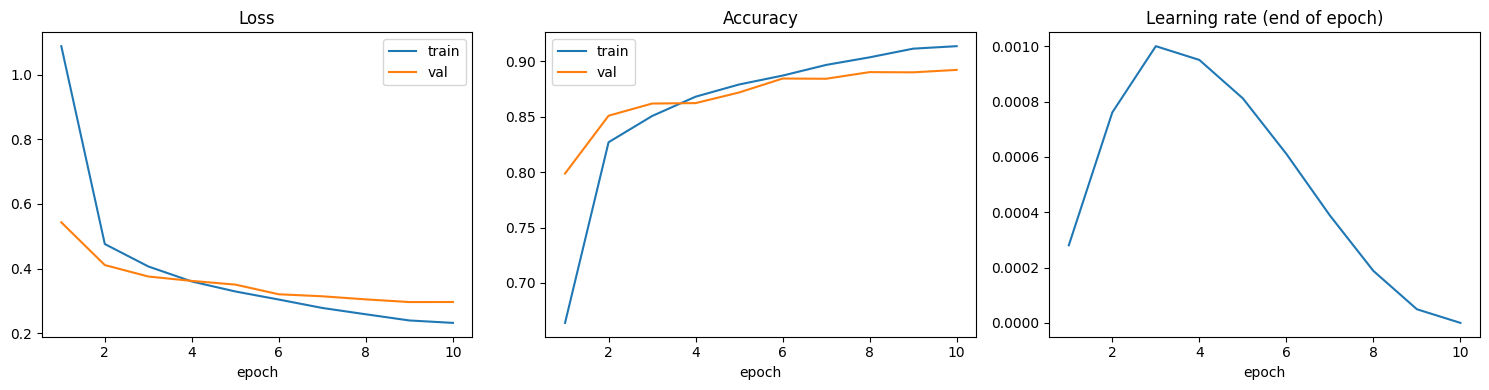

In [12]:
def plot_history(h):
    epochs = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    ax[0].plot(epochs, h["train_loss"], label="train")
    ax[0].plot(epochs, h["val_loss"], label="val")
    ax[0].set_title("Loss"); ax[0].legend()
    ax[1].plot(epochs, h["train_acc"], label="train")
    ax[1].plot(epochs, h["val_acc"], label="val")
    ax[1].set_title("Accuracy"); ax[1].legend()
    ax[2].plot(epochs, h["lr"])
    ax[2].set_title("Learning rate (end of epoch)")
    for a in ax: a.set_xlabel("epoch")
    plt.tight_layout(); plt.show()

plot_history(history)

---

## Part 11: Self-checks

### Check 1: Overfit a single batch

In [13]:
x_b, y_b = next(iter(train_loader))
tiny = [(x_b[:64], y_b[:64])]   # a list works as a "loader": iterable with len()

cfg_tiny = TrainConfig(epochs=100, use_scheduler=False, patience=0,
                       ckpt_dir="ckpt_tiny", log_every=20, grad_clip=None)
t_tiny = Trainer(MLP(dropout=0.0), tiny, tiny, cfg_tiny)
_ = t_tiny.fit()

epoch 20/100 | train loss 0.1140 acc 1.0000 | val loss 0.0937 acc 1.0000 | lr 1.00e-03 | 0.0s *
epoch 40/100 | train loss 0.0023 acc 1.0000 | val loss 0.0021 acc 1.0000 | lr 1.00e-03 | 0.0s *
epoch 60/100 | train loss 0.0006 acc 1.0000 | val loss 0.0006 acc 1.0000 | lr 1.00e-03 | 0.0s *
epoch 80/100 | train loss 0.0004 acc 1.0000 | val loss 0.0004 acc 1.0000 | lr 1.00e-03 | 0.0s *
epoch 100/100 | train loss 0.0003 acc 1.0000 | val loss 0.0003 acc 1.0000 | lr 1.00e-03 | 0.0s *


### Check 2: Resume test

In [14]:
seed_everything(0)
cfg_a = TrainConfig(epochs=3, use_scheduler=False, patience=0, ckpt_dir="ckpt_resume")
t_a = Trainer(MLP(), train_loader, val_loader, cfg_a)
t_a.fit()

cfg_b = TrainConfig(epochs=6, use_scheduler=False, patience=0, ckpt_dir="ckpt_resume")
t_b = Trainer(MLP(), train_loader, val_loader, cfg_b)
t_b.load_checkpoint("last.pt")

same = all(torch.equal(p, q) for p, q in zip(t_a.model.state_dict().values(),
                                              t_b.model.state_dict().values()))
print("weights identical after load:", same)

_ = t_b.fit()

epoch 01/3 | train loss 0.5411 acc 0.8040 | val loss 0.4020 acc 0.8572 | lr 1.00e-03 | 12.5s *
epoch 02/3 | train loss 0.3863 acc 0.8590 | val loss 0.3961 acc 0.8552 | lr 1.00e-03 | 11.7s *
epoch 03/3 | train loss 0.3509 acc 0.8718 | val loss 0.3428 acc 0.8732 | lr 1.00e-03 | 11.7s *
Loaded last.pt: continuing from epoch 4
weights identical after load: True
epoch 04/6 | train loss 0.3293 acc 0.8799 | val loss 0.3544 acc 0.8690 | lr 1.00e-03 | 11.7s
epoch 05/6 | train loss 0.3106 acc 0.8853 | val loss 0.3399 acc 0.8724 | lr 1.00e-03 | 12.0s *
epoch 06/6 | train loss 0.2961 acc 0.8905 | val loss 0.3383 acc 0.8774 | lr 1.00e-03 | 12.3s *


### Check 3: Seed test

In [15]:
def run_once(seed):
    seed_everything(seed)
    gen = torch.Generator().manual_seed(seed)
    loader = DataLoader(train_set, batch_size=128, shuffle=True, num_workers=0, generator=gen)
    cfg = TrainConfig(epochs=1, use_scheduler=False, patience=0,
                      ckpt_dir="ckpt_seed", log_every=100)
    t = Trainer(MLP(), loader, val_loader, cfg)
    t.fit()
    return t.history["train_loss"][-1]

a, b, c = run_once(1), run_once(1), run_once(2)
print(a, b, c)
print("same seed close:", abs(a - b) < 1e-5, "| different seed differs:", abs(a - c) > 1e-6)

0.5467144988016649 0.5467144988016649 0.5393940212856639
same seed close: True | different seed differs: True


### Check 4: Device test

In [16]:
cfg_cpu = TrainConfig(epochs=1, device="cpu", use_scheduler=False, patience=0,
                      ckpt_dir="ckpt_cpu", log_every=1)
_ = Trainer(MLP(), tiny, tiny, cfg_cpu).fit()

epoch 01/1 | train loss 2.2833 acc 0.1406 | val loss 2.0669 acc 0.4844 | lr 1.00e-03 | 0.0s *
